# Assignment 1: Data Profiling (EDA) Report

**Course:** TTTC3213 DATA ENGINEERING

**Dataset:** Nike Sales Uncleaned Dataset

**Team Members:**
1. NURALLYSHA AYUNI BINTI SHAPARIN - A216487
2. DAMIA ZAHIDAH BINTI MAHADZIR - A216557
3. NUR ADLYNA BATRISYIA BINTI ROSMADI - A216765

## 1. Scenario

Global retail managers at Nike want to analyze online sales performance, channel revenue, and regional product demand across customer demographics to optimize inventory allocation and pricing strategies. This assignment evaluates the data quality of Nike sales records by identifying missing values, inconsistent formats, duplicate identifiers, invalid values, and outliers.

## 2. Data Source

Kaggle: [Nike Sales](https://www.kaggle.com/datasets/nayakganesh007/nike-sales-uncleaned-dataset)

In [ ]:
print("Nike Sales Data Profiling")

Nike Sales Data Profiling


## 3. Data Profiling and Issue Handling

### 3.1 Importing Libraries

The following Python libraries are used to inspect the
dataset, identify data quality problems, handle missing
values, and create diagnostic visualisations.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 3.2 Loading the Dataset

The Nike sales dataset is loaded from the CSV file stored
in the project repository.

In [ ]:
df = pd.read_csv("Nike_Sales.csv")

df.head()

,Order_ID,Gender_Category,Product_Line,Product_Name,Size,Units_Sold,MRP,Discount_Applied,Revenue,Order_Date,Sales_Channel,Region,Profit
0,2000,Kids,Training,SuperRep Go,M,NaN,NaN,0.47,0.0,2024-03-09,Online,bengaluru,-770.45
1,2001,Women,Soccer,Tiempo Legend,M,3.0,4957.93,NaN,0.0,2024-07-09,Retail,Hyd,-112.53
2,2002,Women,Soccer,Premier III,M,4.0,NaN,NaN,0.0,NaN,Retail,Mumbai,3337.34
3,2003,Kids,Lifestyle,Blazer Mid,L,NaN,9673.57,NaN,0.0,04-10-2024,Online,Pune,3376.85
4,2004,Kids,Running,React Infinity,XL,NaN,NaN,NaN,0.0,2024/09/12,Retail,Delhi,187.89


### 3.3 Initial Dataset Inspection

The dataset is inspected to determine its dimensions,
column names, data types, and overall structure before
any cleaning is performed.

In [ ]:
# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Display data types and non-null counts
print("\nDataset information:")
df.info()

# Display basic descriptive statistics
print("\nDescriptive statistics:")
display(df.describe(include="all").T)

Dataset shape: (2500, 13)

Column names:
['Order_ID', 'Gender_Category', 'Product_Line', 'Product_Name', 'Size', 'Units_Sold', 'MRP', 'Discount_Applied', 'Revenue', 'Order_Date', 'Sales_Channel', 'Region', 'Profit']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          2500 non-null   int64  
 1   Gender_Category   2500 non-null   str    
 2   Product_Line      2500 non-null   str    
 3   Product_Name      2500 non-null   str    
 4   Size              1990 non-null   str    
 5   Units_Sold        1265 non-null   float64
 6   MRP               1246 non-null   float64
 7   Discount_Applied  832 non-null    float64
 8   Revenue           2500 non-null   float64
 9   Order_Date        1884 non-null   str    
 10  Sales_Channel     2500 non-null   str    
 11  Region            2500 non-null   str    
 12  Pro

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Order_ID,2500.0,NaN,NaN,NaN,3194.3524,749.972638,2000.0,2534.75,3192.5,3841.25,4499.0
Gender_Category,2500,3,Kids,841,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Line,2500,5,Training,546,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Name,2500,20,SuperRep Go,148,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Size,1990,10,L,513,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Units_Sold,1265.0,NaN,NaN,NaN,1.482213,1.696947,-1.0,0.0,2.0,3.0,4.0
MRP,1246.0,NaN,NaN,NaN,6039.863395,2315.746826,2006.63,4038.9025,6110.03,8022.1875,9996.22
Discount_Applied,832.0,NaN,NaN,NaN,0.631022,0.3655,0.0,0.32,0.615,0.9625,1.25
Revenue,2500.0,NaN,NaN,NaN,274.873716,2023.77355,-7561.59,0.0,0.0,0.0,37169.35
Order_Date,1884,1008,17-11-2024,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 3.4 Missing Value Analysis

Missing values are identified and quantified for each
column to determine which fields require further
investigation or treatment.

In [ ]:
# Count missing values in each column
missing_count = df.isnull().sum()

# Calculate the percentage of missing values
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Combine the results into a summary table
missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage (%)": missing_percentage.round(2)
})

# Display columns with missing values first
missing_summary = missing_summary.sort_values(
    by="Missing Count",
    ascending=False
)

display(missing_summary)

,Missing Count,Missing Percentage (%)
Discount_Applied,1668,66.72
MRP,1254,50.16
Units_Sold,1235,49.40
Order_Date,616,24.64
Size,510,20.40
Product_Name,0,0.00
Product_Line,0,0.00
Gender_Category,0,0.00
Order_ID,0,0.00
Revenue,0,0.00


### 3.5 Diagnostic Chart 1: Missing Value Heatmap

A missing-value heatmap is used to visualise the
distribution of missing and available values across
the dataset before cleaning.

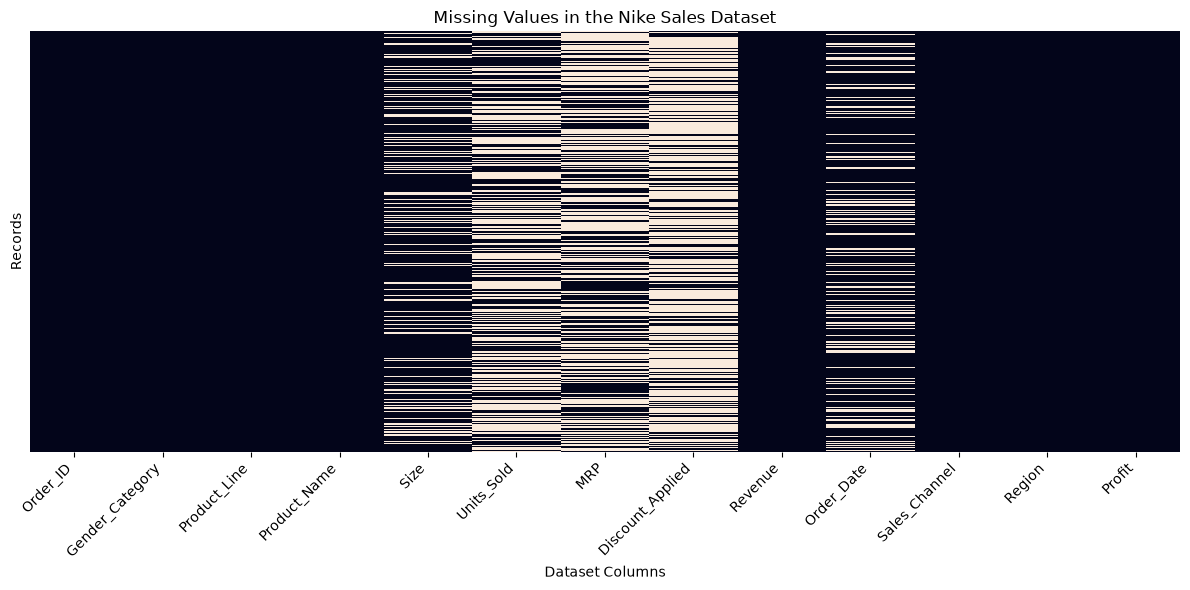

In [ ]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values in the Nike Sales Dataset")
plt.xlabel("Dataset Columns")
plt.ylabel("Records")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

### 3.6 Duplicate Record Analysis

Exact duplicate rows are identified to determine whether
the dataset contains repeated records that may affect
data quality.

In [ ]:
# Count exact duplicate rows
exact_duplicates = df.duplicated().sum()

print("Number of exact duplicate rows:", exact_duplicates)

Number of exact duplicate rows: 0


In [ ]:
# Count rows whose Order_ID has appeared previously
duplicate_order_ids = df["Order_ID"].duplicated().sum()

print("Rows with repeated Order_ID:", duplicate_order_ids)

# Display records with repeated Order_ID values
repeated_orders = df[
    df["Order_ID"].duplicated(keep=False)
].sort_values("Order_ID")

display(repeated_orders.head(20))

Rows with repeated Order_ID: 114


,Order_ID,Gender_Category,Product_Line,Product_Name,Size,Units_Sold,MRP,Discount_Applied,Revenue,Order_Date,Sales_Channel,Region,Profit
0,2000,Kids,Training,SuperRep Go,M,NaN,NaN,0.47,0.00,2024-03-09,Online,bengaluru,-770.45
121,2000,Kids,Running,React Infinity,M,-1.0,NaN,NaN,0.00,2023-11-20,Retail,Kolkata,929.75
211,2000,Kids,Training,Metcon 7,NaN,4.0,NaN,0.94,0.00,2024-02-27,Retail,bengaluru,2372.82
2,2002,Women,Soccer,Premier III,M,4.0,NaN,NaN,0.00,NaN,Retail,Mumbai,3337.34
40,2002,Women,Basketball,Zoom Freak,XL,3.0,5075.22,NaN,0.00,07-03-2025,Retail,Delhi,145.08
391,2002,Women,Training,ZoomX Invincible,XL,4.0,6820.42,NaN,0.00,2024/10/03,Retail,Kolkata,3842.85
1945,2002,Kids,Soccer,Phantom GT,XL,NaN,NaN,NaN,0.00,2025-05-16,Online,Delhi,-789.24
1522,2002,Women,Basketball,Zoom Freak,M,NaN,9041.15,0.44,0.00,NaN,Retail,Kolkata,1597.12
1205,2002,Women,Lifestyle,Dunk Low,7,NaN,NaN,0.24,0.00,2024-12-11,Online,Delhi,912.61
743,2003,Women,Training,ZoomX Invincible,XL,4.0,7850.87,1.02,-628.07,2025/04/01,Online,Kolkata,992.14


### 3.7 Inconsistent Categorical Values

Categorical fields are examined to identify inconsistent
capitalisation, spelling errors, and alternative names
that may refer to the same region.

In [ ]:
categorical_columns = [
    "Gender_Category",
    "Product_Line",
    "Sales_Channel",
    "Region"
]

for column in categorical_columns:
    print(f"\nUnique values in {column}:")
    print(df[column].value_counts(dropna=False))


Unique values in Gender_Category:
Gender_Category
Kids     841
Men      840
Women    819
Name: count, dtype: int64

Unique values in Product_Line:
Product_Line
Training      546
Basketball    507
Lifestyle     501
Running       474
Soccer        472
Name: count, dtype: int64

Unique values in Sales_Channel:
Sales_Channel
Online    1255
Retail    1245
Name: count, dtype: int64

Unique values in Region:
Region
Delhi        438
Mumbai       418
Kolkata      417
Pune         388
bengaluru    220
Bangalore    216
hyderbad     141
Hyd          136
Hyderabad    126
Name: count, dtype: int64


In [ ]:
# Create a working copy for cleaning
df_clean = df.copy()

# Standardise region labels
region_mapping = {
    "bengaluru": "Bengaluru",
    "Bangalore": "Bengaluru",
    "hyderbad": "Hyderabad",
    "Hyd": "Hyderabad",
    "Hyderabad": "Hyderabad"
}

df_clean["Region"] = df_clean["Region"].replace(
    region_mapping
)

# Check the updated categories
print(df_clean["Region"].value_counts())

Region
Delhi        438
Bengaluru    436
Mumbai       418
Kolkata      417
Hyderabad    403
Pune         388
Name: count, dtype: int64


### 3.8 Date Format Standardisation

The Order_Date column contains dates represented
using different formats. The values are converted
into a consistent datetime format to support reliable
date handling and validation.

In [ ]:
# Preserve the original values for comparison
df_clean["Order_Date_Original"] = df_clean["Order_Date"]

# Convert mixed date formats
df_clean["Order_Date"] = pd.to_datetime(
    df_clean["Order_Date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

# Display the converted data type
print("Order_Date data type:", df_clean["Order_Date"].dtype)

# Check missing dates after conversion
print(
    "Missing or unparseable dates:",
    df_clean["Order_Date"].isna().sum()
)

Order_Date data type: datetime64[us]
Missing or unparseable dates: 616


In [ ]:
numeric_columns = [
    "Units_Sold",
    "MRP",
    "Discount_Applied",
    "Revenue",
    "Profit"
]

for column in numeric_columns:
    print(f"\n{column}")
    print(df_clean[column].describe())


Units_Sold
count    1265.000000
mean        1.482213
std         1.696947
min        -1.000000
25%         0.000000
50%         2.000000
75%         3.000000
max         4.000000
Name: Units_Sold, dtype: float64

MRP
count    1246.000000
mean     6039.863395
std      2315.746826
min      2006.630000
25%      4038.902500
50%      6110.030000
75%      8022.187500
max      9996.220000
Name: MRP, dtype: float64

Discount_Applied
count    832.000000
mean       0.631022
std        0.365500
min        0.000000
25%        0.320000
50%        0.615000
75%        0.962500
max        1.250000
Name: Discount_Applied, dtype: float64

Revenue
count     2500.000000
mean       274.873716
std       2023.773550
min      -7561.590000
25%          0.000000
50%          0.000000
75%          0.000000
max      37169.350000
Name: Revenue, dtype: float64

Profit
count    2500.000000
mean     1376.012848
std      1478.671013
min     -1199.450000
25%        93.532500
50%      1371.385000
75%      2660.645000
m

### 3.9 Invalid and Suspicious Numerical Values

Numerical fields are checked for values that may violate
reasonable data constraints, including negative quantities,
discounts outside the expected range, and negative revenue.

Suspicious values are flagged for investigation before
any records are modified or removed.

In [ ]:
# Count potentially invalid or suspicious values
checks = {
    "Negative Units_Sold": (df_clean["Units_Sold"] < 0).sum(),
    "Zero Units_Sold": (df_clean["Units_Sold"] == 0).sum(),
    "Negative MRP": (df_clean["MRP"] < 0).sum(),
    "Discount_Applied above 1": (
        df_clean["Discount_Applied"] > 1
    ).sum(),
    "Negative Revenue": (df_clean["Revenue"] < 0).sum(),
    "Negative Profit": (df_clean["Profit"] < 0).sum()
}

for issue, count in checks.items():
    print(f"{issue}: {count}")

Negative Units_Sold: 205
Zero Units_Sold: 224
Negative MRP: 0
Discount_Applied above 1: 180
Negative Revenue: 53
Negative Profit: 578


In [ ]:
df_clean["Flag_Negative_Units"] = (
    df_clean["Units_Sold"] < 0
)

df_clean["Flag_Discount_Above_1"] = (
    df_clean["Discount_Applied"] > 1
)

df_clean["Flag_Negative_Revenue"] = (
    df_clean["Revenue"] < 0
)

df_clean["Flag_Negative_Profit"] = (
    df_clean["Profit"] < 0
)

# Display the number of flagged records
flag_columns = [
    "Flag_Negative_Units",
    "Flag_Discount_Above_1",
    "Flag_Negative_Revenue",
    "Flag_Negative_Profit"
]

display(
    df_clean[flag_columns].sum().to_frame(
        "Flagged Records"
    )
)

,Flagged Records
Flag_Negative_Units,205
Flag_Discount_Above_1,180
Flag_Negative_Revenue,53
Flag_Negative_Profit,578


### 3.10 Outlier Detection Using the IQR Method

The Interquartile Range method is applied to selected
numerical columns to identify observations that fall
outside the expected statistical bounds.

Detected outliers are flagged for investigation rather
than automatically removed.

In [ ]:
outlier_columns = [
    "MRP",
    "Revenue",
    "Profit"
]

outlier_results = []

for column in outlier_columns:

    # Exclude missing values when calculating quartiles
    series = df_clean[column].dropna()

    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Flag outliers in the original-length column
    outlier_flag = (
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    ) & df_clean[column].notna()

    df_clean[f"{column}_Outlier_Flag"] = outlier_flag

    outlier_results.append({
        "Column": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": int(outlier_flag.sum())
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(2))

,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,MRP,4038.90,8022.19,3983.28,-1936.02,13997.12,0
1,Revenue,0.00,0.00,0.00,0.00,0.00,166
2,Profit,93.53,2660.64,2567.11,-3757.14,6511.31,0


### 3.11 Diagnostic Chart 2: Boxplots for Outlier Detection

Boxplots are used to examine the distributions of MRP,
Revenue, and Profit and to identify observations that
fall outside the typical range of the data.

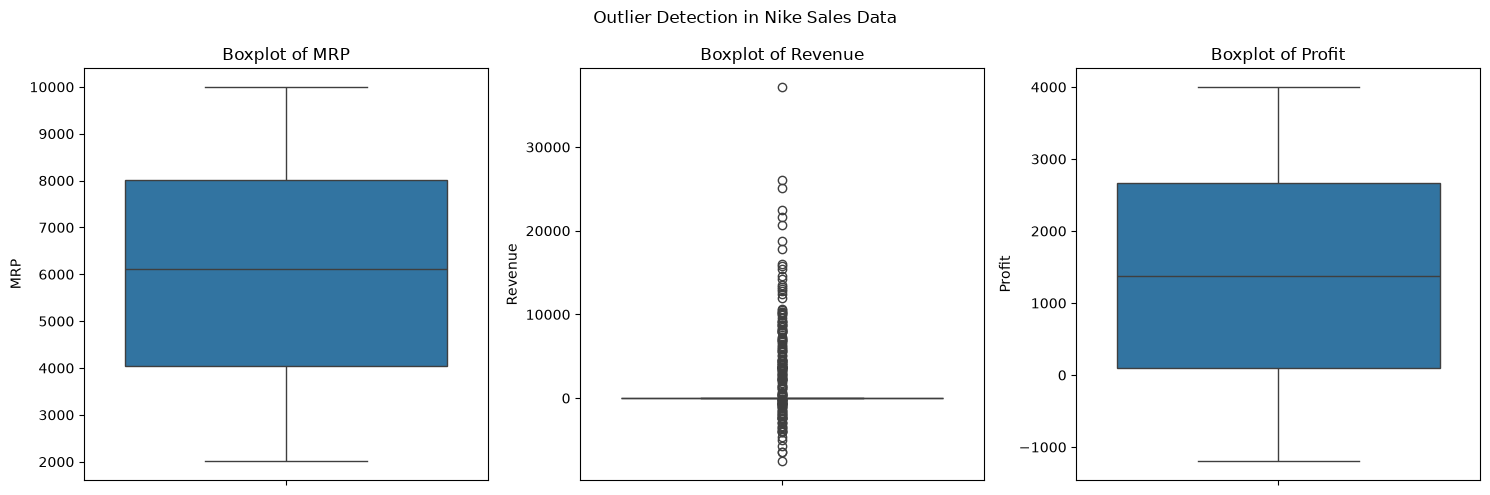

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, column in zip(axes, outlier_columns):
    sns.boxplot(
        y=df_clean[column],
        ax=ax
    )

    ax.set_title(f"Boxplot of {column}")
    ax.set_ylabel(column)

plt.suptitle("Outlier Detection in Nike Sales Data")
plt.tight_layout()
plt.show()

### 3.12 Missing Value Handling

Missing values are retained when their original values
cannot be reliably inferred. Indicator columns are
created to identify missing records and support further
investigation.

Automatic imputation is avoided where it could introduce
unsupported assumptions into the dataset.

In [ ]:
# Record missingness before any further changes
columns_with_missing_values = [
    "Size",
    "Units_Sold",
    "MRP",
    "Discount_Applied",
    "Order_Date"
]

for column in columns_with_missing_values:
    df_clean[f"{column}_Missing"] = (
        df_clean[column].isna()
    )

# Summarise missingness indicators
missing_flags = [
    f"{column}_Missing"
    for column in columns_with_missing_values
]

display(
    df_clean[missing_flags].sum().to_frame(
        "Missing Records"
    )
)

,Missing Records
Size_Missing,510
Units_Sold_Missing,1235
MRP_Missing,1254
Discount_Applied_Missing,1668
Order_Date_Missing,616


### 3.13 Validation of Data Cleaning

The original and cleaned datasets are compared to
verify the effects of the cleaning operations and
confirm that the original records have been preserved.

In [ ]:
data_quality_report = pd.DataFrame({
    "Metric": [
        "Total records",
        "Total columns in original dataset",
        "Exact duplicate rows",
        "Rows with repeated Order_ID",
        "Missing values in original dataset",
        "Negative Units_Sold",
        "Discount_Applied above 1",
        "Negative Revenue",
        "Negative Profit"
    ],
    "Result": [
        len(df),
        len(df.columns),
        df.duplicated().sum(),
        df["Order_ID"].duplicated().sum(),
        df.isnull().sum().sum(),
        (df["Units_Sold"] < 0).sum(),
        (df["Discount_Applied"] > 1).sum(),
        (df["Revenue"] < 0).sum(),
        (df["Profit"] < 0).sum()
    ]
})

display(data_quality_report)

,Metric,Result
0,Total records,2500
1,Total columns in original dataset,13
2,Exact duplicate rows,0
3,Rows with repeated Order_ID,114
4,Missing values in original dataset,5283
5,Negative Units_Sold,205
6,Discount_Applied above 1,180
7,Negative Revenue,53
8,Negative Profit,578


## 5. PII and Bias Risks

### 5.1 Personal Identifiable Information (PII)

The dataset contains order identifiers, product details,
sales regions, sales channels, and transaction-related
values. It does not contain obvious direct personal
identifiers such as customer names, phone numbers,
email addresses, or residential addresses.

However, Order_ID is a transaction identifier and should
not automatically be treated as anonymous personal data
in every possible context. If the dataset were linked to
other records containing customer information, additional
privacy risks could arise.

For this assignment, access to the dataset should be
limited to the intended analytical purpose, and any
future integration with customer records should follow
appropriate privacy and data protection practices.

### 5.2 Sampling and Representation Bias

The dataset contains regional labels associated with
Indian cities, including Delhi, Mumbai, Kolkata, Pune,
Bengaluru, and Hyderabad. The records therefore may not
represent Nike sales across all countries, markets,
customer groups, or sales channels.

Although the dataset includes Gender_Category and
Sales_Channel, the distribution of these categories
does not establish that the records are representative
of the wider customer population.

Furthermore, the dataset does not provide sufficient
information about its sampling method, collection
period, or data-generation process to establish how
representative the records are.

These limitations should be considered before using
the dataset to make general conclusions about Nike
customers or sales.

## 6. Conclusion

The Nike sales dataset contains 2,500 records and 13
columns. The profiling process identified substantial
missingness in several fields, repeated order identifiers,
inconsistent regional labels, mixed date formats, and
potentially invalid numerical values.

The dataset also contains statistical outliers that
require further investigation. Missing values were
flagged rather than automatically imputed, regional
labels were standardised, and suspicious numerical
values and outliers were flagged for review.

The dataset may be suitable for demonstrating data
profiling and exploratory data quality assessment.
However, it should not be considered fully validated
for reliable sales reporting until the missing values,
repeated identifiers, date conventions, and suspicious
numerical records have been investigated further.

The main limitation is the lack of a complete data
dictionary and transaction-level documentation.
Consequently, some observations can only be classified
as potential quality issues rather than confirmed errors.